# 03 · Logistic regression and classification metrics

Logistic regression models the **log-odds** linearly:

$$\log\frac{p}{1-p} = \beta_0 + \beta^\top x \quad\Longleftrightarrow\quad p = \sigma(\beta_0 + \beta^\top x)$$

It is fitted by minimising **log loss**, so its probabilities are usually well calibrated, which matters when you act on them (pricing, risk, expected value).
In sklearn it is regularised by default (`C` = 1/penalty strength; **smaller C = more regularisation**), so scale your features.

**In this notebook:** fitting, probabilities vs labels, ROC/PR curves, calibration, choosing a threshold, class imbalance, multiclass.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_breast_cancer(return_X_y=True, as_frame=True)
y = 1 - y        # make 1 = malignant (the class we care about)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print(X.shape, f"positive rate = {y.mean():.2f}")

clf = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=20, cv=5, scoring="neg_log_loss", max_iter=5000))
clf.fit(X_train, y_train)
proba = clf.predict_proba(X_test)[:, 1]
print("chosen C:", clf[-1].C_[0].round(3))

(569, 30) positive rate = 0.37


chosen C: 0.616


## 1. Metrics: judge the probabilities, not just the labels

In [3]:
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, average_precision_score, brier_score_loss, confusion_matrix

pred = (proba >= 0.5).astype(int)
print(f"accuracy  : {accuracy_score(y_test, pred):.3f}")
print(f"ROC AUC   : {roc_auc_score(y_test, proba):.3f}   (ranking quality)")
print(f"PR AUC    : {average_precision_score(y_test, proba):.3f}   (focus on positives)")
print(f"log loss  : {log_loss(y_test, proba):.3f}   (baseline = {log_loss(y_test, np.full_like(proba, y_train.mean())):.3f})")
print(f"Brier     : {brier_score_loss(y_test, proba):.3f}")
print("confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, pred))

accuracy  : 0.977
ROC AUC   : 0.998   (ranking quality)
PR AUC    : 0.997   (focus on positives)
log loss  : 0.066   (baseline = 0.661)
Brier     : 0.017
confusion matrix [[TN FP] [FN TP]]:
 [[107   0]
 [  4  60]]


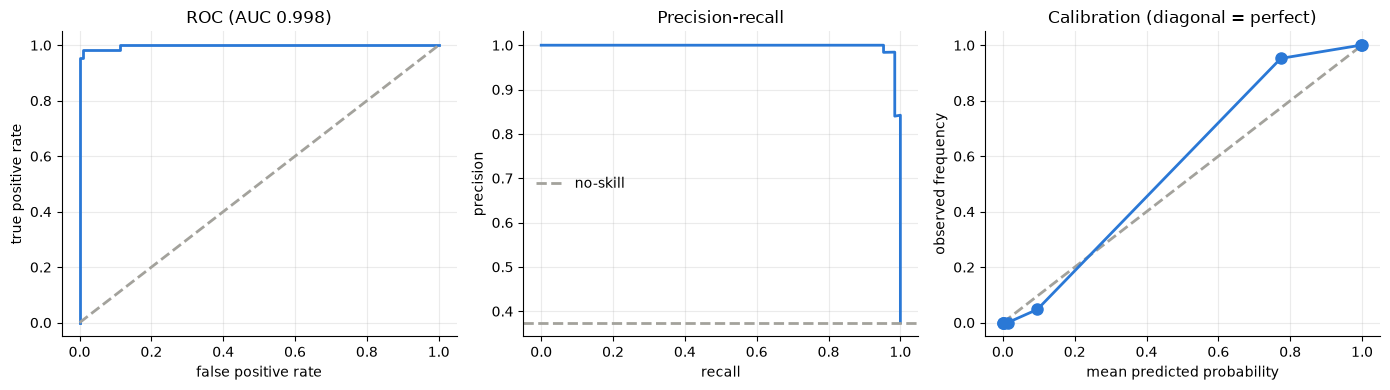

In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=8, strategy="quantile")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(fpr, tpr, color=PALETTE[0]); axes[0].plot([0, 1], [0, 1], color=GREY, ls="--")
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title=f"ROC (AUC {roc_auc_score(y_test, proba):.3f})")
axes[1].plot(rec, prec, color=PALETTE[0]); axes[1].axhline(y_test.mean(), color=GREY, ls="--", label="no-skill")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall"); axes[1].legend()
axes[2].plot([0, 1], [0, 1], color=GREY, ls="--"); axes[2].plot(mean_pred, frac_pos, "o-", color=PALETTE[0], ms=8)
axes[2].set(xlabel="mean predicted probability", ylabel="observed frequency", title="Calibration (diagonal = perfect)")
plt.tight_layout()
plt.show()

## 2. Choosing a threshold

0.5 is just a default. Pick the threshold that minimises **expected cost**. Say a missed malignancy (FN) costs 10× a false alarm (FP):

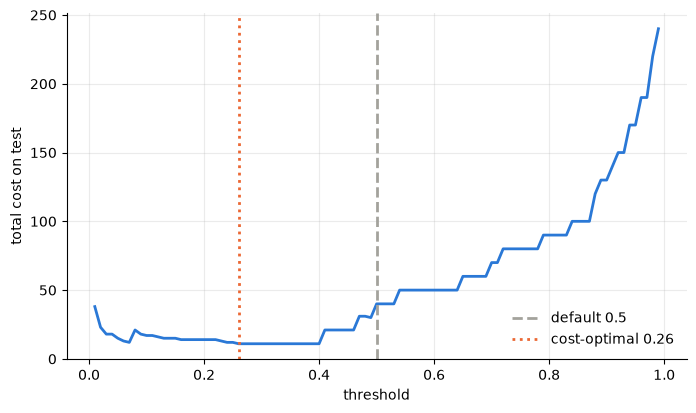

In [5]:
thresholds = np.linspace(0.01, 0.99, 99)
cost_fn, cost_fp = 10, 1
costs = [cost_fn * ((proba < t) & (y_test == 1)).sum() + cost_fp * ((proba >= t) & (y_test == 0)).sum() for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

fig, ax = plt.subplots()
ax.plot(thresholds, costs, color=PALETTE[0])
ax.axvline(0.5, color=GREY, ls="--", label="default 0.5")
ax.axvline(best_t, color=PALETTE[1], ls=":", label=f"cost-optimal {best_t:.2f}")
ax.set_xlabel("threshold"); ax.set_ylabel("total cost on test"); ax.legend()
plt.show()

With calibrated probabilities the cost-optimal threshold is analytic: predict positive when $p > \frac{C_{FP}}{C_{FP}+C_{FN}}$ (here $1/11 \approx 0.09$). In practice, tune it on validation data, not on the test set as we did here for illustration.

## 3. Interpreting coefficients

On standardised features, $e^{\beta_j}$ is the **odds ratio** for a one-standard-deviation increase in $x_j$.

In [6]:
coef = pd.Series(clf[-1].coef_[0], index=X.columns)
top = coef.abs().sort_values(ascending=False).index[:8]
pd.DataFrame({"coef": coef[top], "odds ratio per +1 sd": np.exp(coef[top])})

,coef,odds ratio per +1 sd
worst texture,1.1476,3.1506
radius error,0.9855,2.6792
worst symmetry,0.9164,2.5003
worst area,0.7517,2.1207
area error,0.7513,2.1198
worst radius,0.7498,2.1167
compactness error,-0.7302,0.4818
mean concave points,0.7153,2.0447


## 4. Class imbalance

With 5% positives, "always predict negative" scores 95% accuracy. Use AUC / PR AUC / log loss, and consider:
- `class_weight="balanced"` (reweights the loss, which *shifts* the probabilities upward, so it's no longer calibrated)
- or keep the model unweighted and **move the threshold** (often simpler and keeps calibration)
- stratified splits so every fold has positives

In [7]:
from sklearn.datasets import make_classification

Xi, yi = make_classification(n_samples=20000, n_features=20, n_informative=5, weights=[0.95], flip_y=0.01, random_state=SEED)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=SEED)

rows = []
for cw in [None, "balanced"]:
    m = make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw, max_iter=2000)).fit(Xi_tr, yi_tr)
    p = m.predict_proba(Xi_te)[:, 1]
    rows.append({"class_weight": str(cw), "accuracy@0.5": accuracy_score(yi_te, p > 0.5),
                 "recall@0.5": ((p > 0.5) & (yi_te == 1)).sum() / yi_te.sum(),
                 "ROC AUC": roc_auc_score(yi_te, p), "PR AUC": average_precision_score(yi_te, p),
                 "mean predicted p": p.mean(), "actual rate": yi_te.mean()})
pd.DataFrame(rows).set_index("class_weight")

,accuracy@0.5,recall@0.5,ROC AUC,PR AUC,mean predicted p,actual rate
class_weight,,,,,,
None,0.9443,0.0183,0.7846,0.1941,0.0551,0.0547
balanced,0.7565,0.7409,0.8093,0.1749,0.3775,0.0547


Ranking quality (ROC/PR AUC) barely moves, but the labels at 0.5 and the average predicted probability change completely: the unweighted model's mean probability matches the true rate, the balanced one's is ~7× too high. Reweighting mostly changes *where the threshold sits*, not how well the model separates the classes.

## 5. Multiclass

`LogisticRegression` handles $K$ classes with a softmax (multinomial) model automatically.

In [8]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score

Xw, yw = load_wine(return_X_y=True)
m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
print(f"wine (3 classes) CV accuracy: {cross_val_score(m, Xw, yw, cv=5).mean():.3f}")
print(f"CV log loss: {-cross_val_score(m, Xw, yw, cv=5, scoring='neg_log_loss').mean():.3f}")

wine (3 classes) CV accuracy: 0.983
CV log loss: 0.073


## Takeaways
- Logistic regression = the Ridge of classification: fast, calibrated, strong baseline.
- Evaluate with **log loss / AUC**, then choose the threshold for the business cost.
- Imbalance: right metric + stratification first; reweighting or threshold-moving second.
- If calibration matters for a tree model, wrap it with `CalibratedClassifierCV`.